# Проект модуля. Система поиска товаров на основе дообученной CLIP-модели

Нужно дообучить CLIP на датасете товаров из магазинов одежды и реализовать поиск изображений по англоязычным текстовым запросам.

## 1. Работа с данными

Для обучения используем столбцы `image` и `description` из `data.csv`.

In [ ]:
from pathlib import Path
from textwrap import fill

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset

import numpy as np
import torch
import torch.nn.functional as F
from transformers import CLIPModel, CLIPProcessor

from dataclasses import dataclass
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from transformers import get_cosine_schedule_with_warmup

DATASET_HANDLE = 'nirmalsankalana/fashion-product-text-images-dataset'
MODEL_NAME = 'openai/clip-vit-base-patch32'

dataset_path = Path(kagglehub.dataset_download(DATASET_HANDLE))
csv_path = dataset_path / 'data.csv'
image_dir = dataset_path / 'data'

### Первичный обзор

In [22]:
df = pd.read_csv(csv_path)
print(f'Размер таблицы: {df.shape}')
display(df.head())

summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isna().sum(),
    'unique': df.nunique(dropna=True),
})
display(summary)
print(f"Полных дубликатов: {df.duplicated().sum()}")
print(f"Дубликатов image-description: {df.duplicated(['image', 'description']).sum()}")

Размер таблицы: (44441, 4)


,image,description,display name,category
0,3238.jpg,"Round toed, black sports shoes with red accent...",Puma Men Black 65CC Lo Ducati Sports Shoes,Sports Shoes
1,43044.jpg,Style Note Built with the breathability and ze...,Nike Men Charcoal Grey Shorts,Shorts
2,54018.jpg,Teal handbag that has stitch detailing with a...,Kiara Women Teal Handbag,Handbags
3,8141.jpg,"Perfectly stylish, this fastrack analog wrist ...",Fastrack Women Freestyle Sports Analog Steel B...,Watches
4,22245.jpg,These id mid-top chukka shoes add a fresh spin...,ID Men Brown Casual Shoes,Casual Shoes


,dtype,missing,unique
image,str,0,44441
description,str,281,38856
display name,str,7,31131
category,str,0,142


Полных дубликатов: 0
Дубликатов image-description: 0


### Разрешения изображений

Проверяем все файлы: так мы одновременно исследуем размеры и обнаруживаем отсутствующие или повреждённые изображения.

Проверено: 44,441; повреждено/отсутствует: 0


,width,height
count,44441.0,44441.0
mean,1080.0,1440.0
std,0.0,0.0
min,1080.0,1440.0
25%,1080.0,1440.0
50%,1080.0,1440.0
75%,1080.0,1440.0
max,1080.0,1440.0


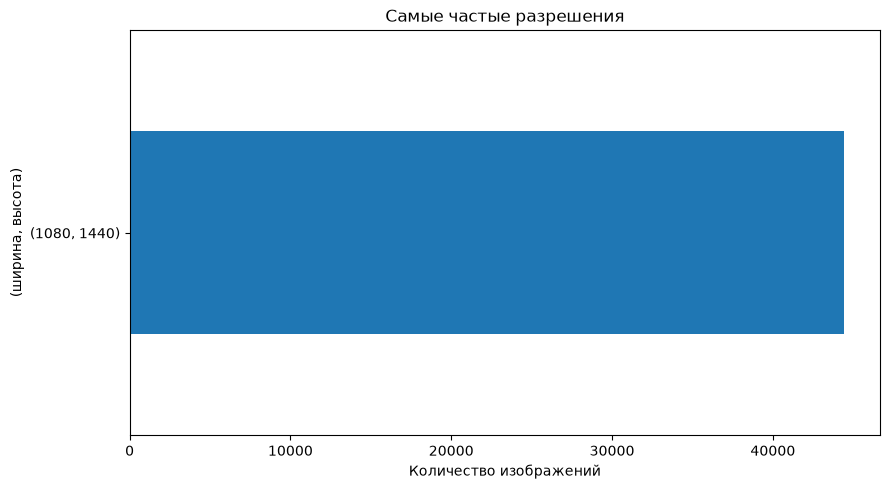

In [23]:
image_info = []
broken_images = []

for image_name in df['image'].dropna().unique():
    image_path = image_dir / str(image_name)
    try:
        with Image.open(image_path) as image:
            width, height = image.size
        image_info.append((image_name, width, height))
    except (FileNotFoundError, UnidentifiedImageError, OSError):
        broken_images.append(image_name)

resolution_df = pd.DataFrame(image_info, columns=['image', 'width', 'height'])
print(f'Проверено: {len(resolution_df):,}; повреждено/отсутствует: {len(broken_images):,}')
display(resolution_df[['width', 'height']].describe().round(1))

top_resolutions = resolution_df.value_counts(['width', 'height']).head(10).sort_values()
ax = top_resolutions.plot(kind='barh', figsize=(9, 5), title='Самые частые разрешения')
ax.set(xlabel='Количество изображений', ylabel='(ширина, высота)')
plt.tight_layout()
plt.show()

### Случайные изображения и описания

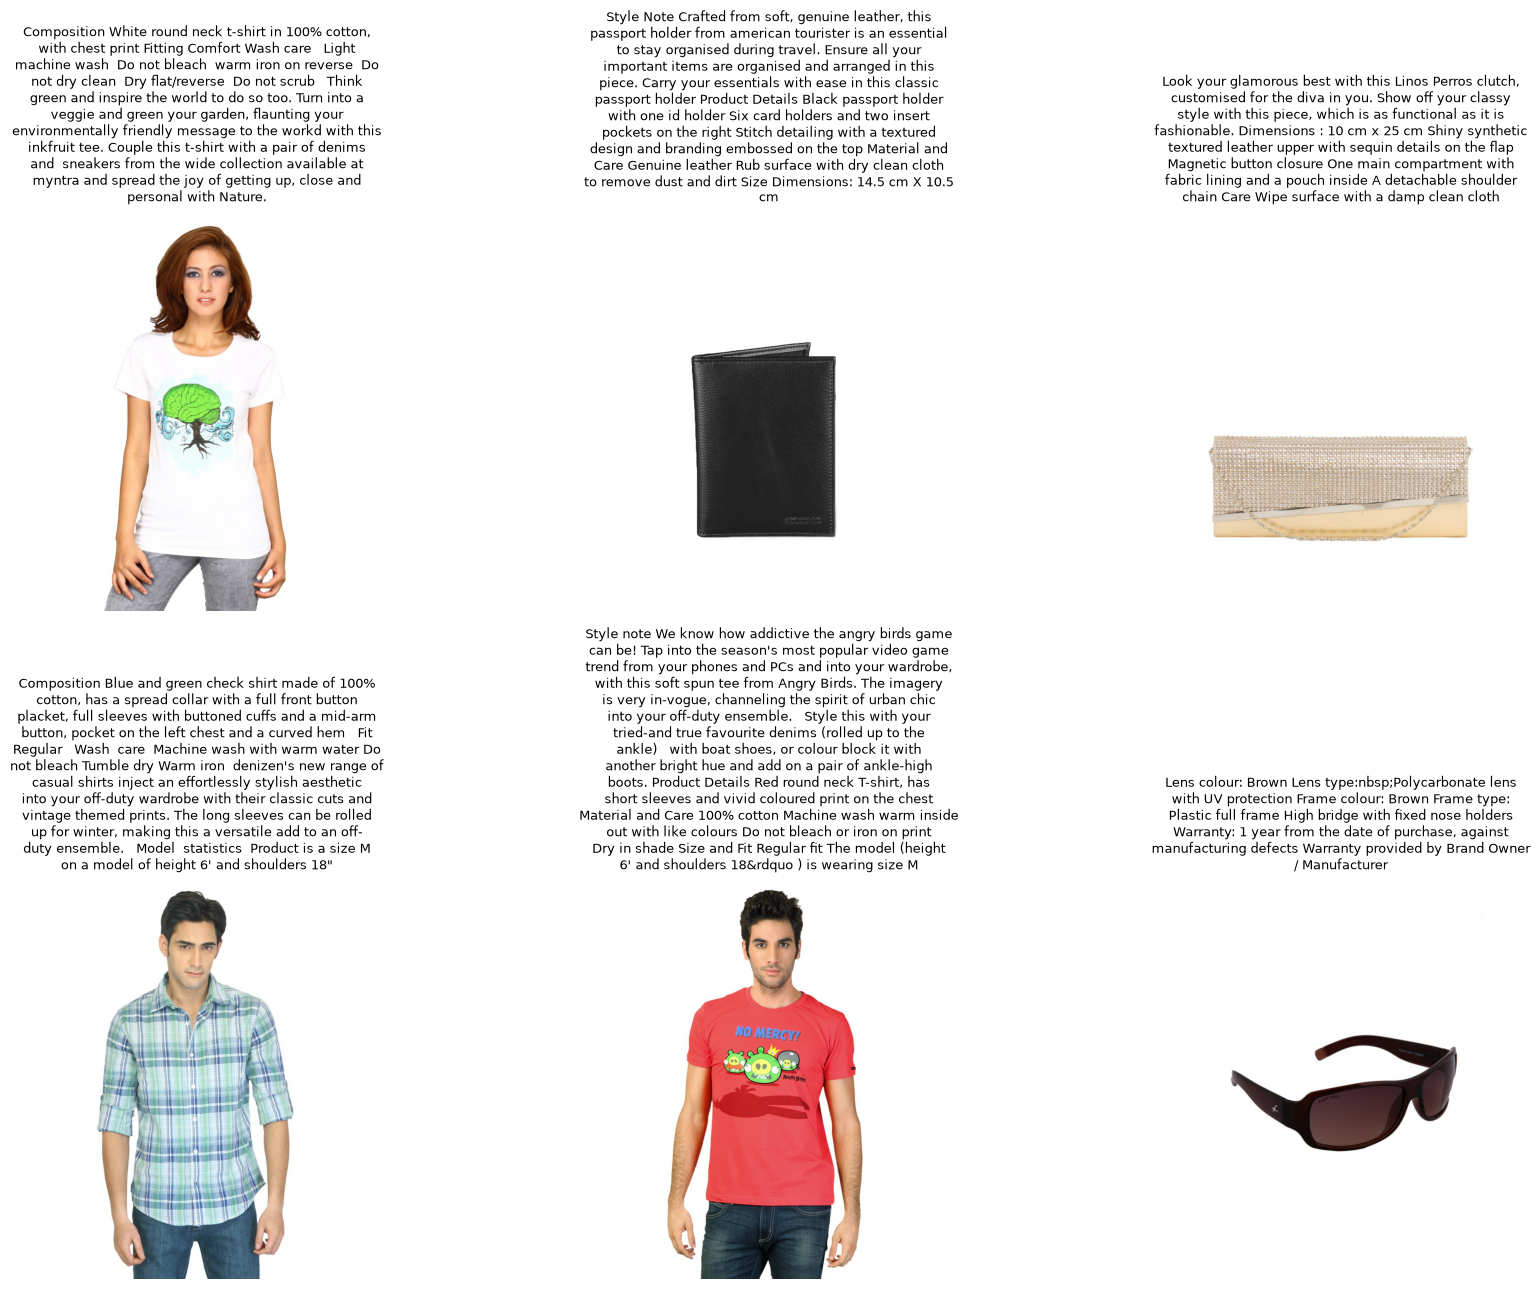

In [24]:
visual_sample = df.dropna(subset=['image', 'description']).sample(6)
fig, axes = plt.subplots(2, 3, figsize=(18, 13))
for ax, (_, row) in zip(axes.flat, visual_sample.iterrows()):
    with Image.open(image_dir / row['image']) as image:
        ax.imshow(image.convert('RGB'))
    ax.set_title(fill(str(row['description']), width=55), fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

**Наблюдения.** Большинство описаний называют тип вещи, цвет и заметные детали и подходят для обучения поиска. Тексты, однако, неоднородны: некоторые перегружены рекламными фразами, составом, размерами и правилами ухода, которые нельзя определить по изображению. Встречаются малоинформативные описания только с инструкциями по уходу. Пока сохраняем исходный текст, а влияние дополнительной очистки можно проверить отдельным экспериментом.

### Очистка и разбиение данных

Удаляем пропуски, пустые строки, повторяющиеся пары и записи без читаемого изображения. В тестовую выборку выделяем 10% данных.

In [25]:
clean_df = df[['image', 'description']].copy()
clean_df = clean_df.dropna(subset=['image', 'description'])
clean_df['image'] = clean_df['image'].astype(str).str.strip()
clean_df['description'] = clean_df['description'].astype(str).str.strip()
clean_df = clean_df.loc[clean_df['image'].ne('') & clean_df['description'].ne('')]
clean_df = clean_df.drop_duplicates(subset=['image', 'description'])
clean_df = clean_df.loc[~clean_df['image'].isin(broken_images)].reset_index(drop=True)

train_df, test_df = train_test_split(
    clean_df, test_size=0.10, shuffle=True
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f'До очистки: {len(df):,}')
print(f'После очистки: {len(clean_df):,}')
print(f'Train: {len(train_df):,} ({len(train_df) / len(clean_df):.1%})')
print(f'Test:  {len(test_df):,} ({len(test_df) / len(clean_df):.1%})')

До очистки: 44,441
После очистки: 44,158
Train: 39,742 (90.0%)
Test:  4,416 (10.0%)


### Класс датасета

Без `processor` класс возвращает RGB-изображение и текст. После подключения `CLIPProcessor` каждый элемент будет содержать готовые `pixel_values`, `input_ids` и `attention_mask`.

In [26]:
class FashionProductDataset(Dataset):
    def __init__(self, dataframe, image_dir, processor=None, transform=None):
        self.dataframe = dataframe[['image', 'description']].reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.processor = processor
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        with Image.open(self.image_dir / row['image']) as image:
            image = image.convert('RGB')

        text = row['description']
        if self.processor is not None:
            encoded = self.processor(
                text=[text], images=image, return_tensors='pt',
                padding='max_length', truncation=True,
            )
            return {key: value.squeeze(0) for key, value in encoded.items()}

        if self.transform is not None:
            image = self.transform(image)
        return {'image': image, 'text': text, 'image_name': row['image']}

In [27]:
train_dataset = FashionProductDataset(train_df, image_dir)
test_dataset = FashionProductDataset(test_df, image_dir)
sample = train_dataset[0]

print(f'Train dataset size: {len(train_dataset):,}')
print(f'Test dataset size: {len(test_dataset):,}')
print(f"Sample: {sample['image_name']}, size={sample['image'].size}")
print(f"Text: {sample['text'][:250]}")

Train dataset size: 39,742
Test dataset size: 4,416
Sample: 34239.jpg, size=(1080, 1440)
Text: White polo T-shirt, has a polo collar, short button placket, chest pocket, short sleeves


## 2. Работа с предобученной CLIP-моделью

Загрузим openai/clip-vit-base-patch32 из transformers и проверим исходную модель на нескольких объектах тестовой выборки до дообучения. Это будет baseline для последующего сравнения.

In [28]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

processor = CLIPProcessor.from_pretrained(MODEL_NAME)
model = CLIPModel.from_pretrained(MODEL_NAME).to(device)
model.eval()

print(f'Model: {MODEL_NAME}')
print(f'Device: {device}')

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 44194.99it/s]


Model: openai/clip-vit-base-patch32
Device: cuda


### CLIP-скоры для примеров

Для каждой картинки сопоставим все описания мини-батча и рассчитаем:

- cosine_score — косинусную близость правильной пары;
- clip_logit — близость, масштабированную обучаемой температурой CLIP;
- match_probability — softmax-вероятность правильного описания среди описаний текущего мини-батча. Это относительная, а не абсолютная вероятность соответствия.

In [30]:
N_EXAMPLES = 6
clip_sample = test_df.sample(N_EXAMPLES).reset_index(drop=True)

clip_images = []
for image_name in clip_sample['image']:
    with Image.open(image_dir / image_name) as image:
        clip_images.append(image.convert('RGB'))
clip_texts = clip_sample['description'].tolist()

inputs = processor(
    text=clip_texts,
    images=clip_images,
    return_tensors='pt',
    padding=True,
    truncation=True,
)
inputs = {key: value.to(device) for key, value in inputs.items()}

with torch.inference_mode():
    outputs = model(**inputs)

image_embeds = F.normalize(outputs.image_embeds, dim=-1)
text_embeds = F.normalize(outputs.text_embeds, dim=-1)
cosine_scores = image_embeds @ text_embeds.T
clip_logits = outputs.logits_per_image
match_probabilities = clip_logits.softmax(dim=1)

pair_indices = torch.arange(N_EXAMPLES, device=device)
score_table = clip_sample.copy()
score_table['cosine_score'] = cosine_scores[pair_indices, pair_indices].cpu().numpy()
score_table['clip_logit'] = clip_logits[pair_indices, pair_indices].cpu().numpy()
score_table['match_probability'] = match_probabilities[pair_indices, pair_indices].cpu().numpy()
score_table['top1_correct_in_batch'] = (clip_logits.argmax(dim=1) == pair_indices).cpu().numpy()

display(score_table[
    ['image', 'cosine_score', 'clip_logit', 'match_probability', 'top1_correct_in_batch']
].round(4))
print(f"Top-1 accuracy внутри мини-батча: {score_table['top1_correct_in_batch'].mean():.1%}")

,image,cosine_score,clip_logit,match_probability,top1_correct_in_batch
0,51505.jpg,0.2646,26.462200,0.9935,True
1,44168.jpg,0.3435,34.354099,1.0000,True
2,30325.jpg,0.2049,20.487200,0.4161,False
3,14995.jpg,0.2438,24.384501,0.0834,False
4,18969.jpg,0.3454,34.541000,0.9999,True
5,3620.jpg,0.2944,29.436800,1.0000,True


Top-1 accuracy внутри мини-батча: 66.7%


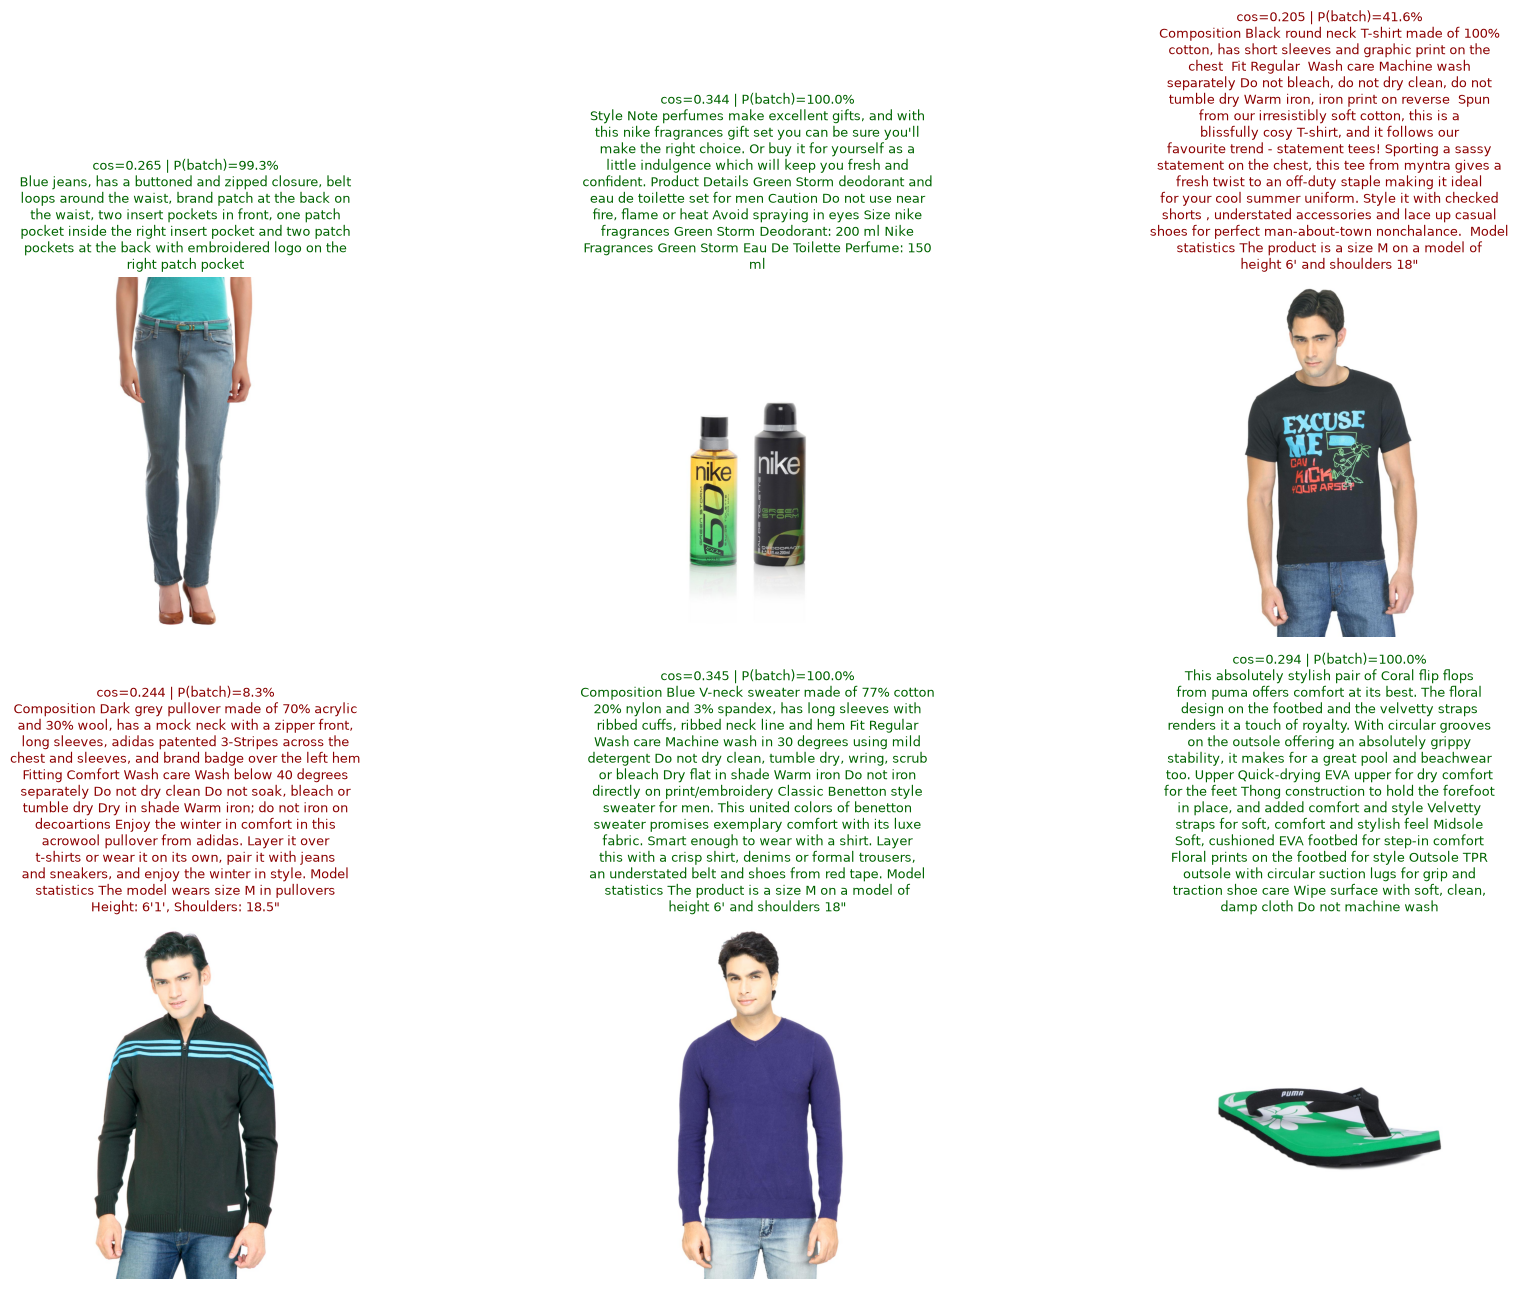

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(18, 13))
for idx, (ax, image) in enumerate(zip(axes.flat, clip_images)):
    row = score_table.iloc[idx]
    ax.imshow(image)
    title = (
        f"cos={row['cosine_score']:.3f} | "
        f"P(batch)={row['match_probability']:.1%}\n"
        f"{fill(row['description'], width=52)}"
    )
    color = 'darkgreen' if row['top1_correct_in_batch'] else 'darkred'
    ax.set_title(title, fontsize=9, color=color)
    ax.axis('off')

plt.tight_layout()
plt.show()

### Матрица сходства

Диагональ соответствует исходным парам image-description. Если CLIP хорошо различает примеры, крупные значения должны концентрироваться на диагонали. Значения вне диагонали показывают сложные негативные пары — разные товары с похожими описаниями.

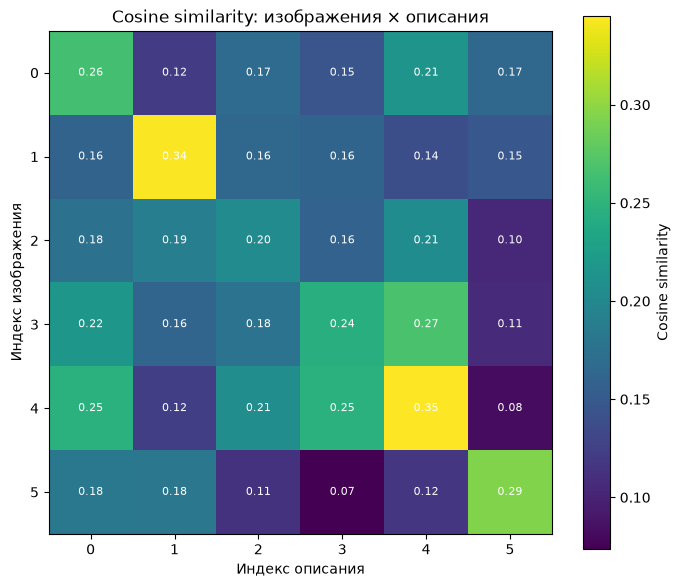

In [32]:
similarity_matrix = cosine_scores.cpu().numpy()
fig, ax = plt.subplots(figsize=(7, 6))
heatmap = ax.imshow(similarity_matrix, cmap='viridis')
ax.set(
    xticks=np.arange(N_EXAMPLES),
    yticks=np.arange(N_EXAMPLES),
    xlabel='Индекс описания',
    ylabel='Индекс изображения',
    title='Cosine similarity: изображения × описания',
)

for i in range(N_EXAMPLES):
    for j in range(N_EXAMPLES):
        ax.text(
            j, i, f'{similarity_matrix[i, j]:.2f}',
            ha='center', va='center', color='white', fontsize=8,
        )

fig.colorbar(heatmap, ax=ax, label='Cosine similarity')
plt.tight_layout()
plt.show()

**Интерпретация baseline.** Чем выше cosine_score правильной пары относительно остальных элементов её строки, тем лучше исходная CLIP сопоставляет изображение и описание. Абсолютные значения зависят от модели и данных, поэтому основной ориентир — ранжирование. Длинные описания обрезаются до лимита текстового энкодера CLIP (77 токенов), и важные характеристики в конце текста могут потеряться. После дообучения результаты следует сравнить на той же фиксированной тестовой выборке.

## 3. Дообучение CLIP

Используем стандартный симметричный CLIP loss через return_loss=True. Правильные пары находятся на диагонали матрицы сходства. CLIP score — среднее диагональных logits_per_image, то есть масштабированная температурой близость правильных пар.

In [ ]:
@dataclass
class TrainingConfig:
    batch_size: int = 64
    epochs: int = 4
    learning_rate: float = 5e-6
    weight_decay: float = 1e-2
    warmup_ratio: float = 0.1
    num_workers: int = 0
    checkpoint_dir: Path = Path('checkpoints')

config = TrainingConfig()
config.checkpoint_dir.mkdir(parents=True, exist_ok=True)
config

TrainingConfig(batch_size=64, epochs=4, learning_rate=5e-06, weight_decay=0.01, warmup_ratio=0.1, num_workers=0, checkpoint_dir=WindowsPath('checkpoints'))

In [34]:
def clip_collate_fn(items):
    return processor(
        text=[item['text'] for item in items],
        images=[item['image'] for item in items],
        return_tensors='pt', padding=True, truncation=True,
    )

loader_kwargs = dict(
    batch_size=config.batch_size,
    num_workers=config.num_workers,
    pin_memory=device.type == 'cuda',
    collate_fn=clip_collate_fn,
)
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)
print(f'Train batches: {len(train_loader):,}; validation batches: {len(test_loader):,}')

Train batches: 621; validation batches: 69


### Функции обучения и валидации

Для каждого батча progress bar показывает текущие и накопленные средние loss и CLIP score. Валидация усредняет score по всей тестовой выборке.

In [35]:
def move_to_device(batch):
    return {key: value.to(device, non_blocking=True) for key, value in batch.items()}

def diagonal_clip_score(outputs):
    return outputs.logits_per_image.diagonal().mean()

def train_one_epoch(model, loader, optimizer, scheduler, scaler, epoch):
    model.train()
    total_loss = total_score = 0.0
    total_examples = 0
    history = []
    progress = tqdm(loader, desc=f'Epoch {epoch} | train')
    for batch_number, batch in enumerate(progress, start=1):
        batch = move_to_device(batch)
        batch_size = batch['pixel_values'].shape[0]
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast(device_type=device.type, enabled=device.type == 'cuda'):
            outputs = model(**batch, return_loss=True)
            loss = outputs.loss
            score = diagonal_clip_score(outputs)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        loss_value, score_value = loss.detach().item(), score.detach().item()
        total_loss += loss_value * batch_size
        total_score += score_value * batch_size
        total_examples += batch_size
        avg_loss, avg_score = total_loss / total_examples, total_score / total_examples
        history.append({
            'epoch': epoch, 'batch': batch_number,
            'loss': loss_value, 'clip_score': score_value,
            'running_loss': avg_loss, 'running_clip_score': avg_score,
        })
        progress.set_postfix(
            loss=f'{loss_value:.4f}', avg_loss=f'{avg_loss:.4f}',
            score=f'{score_value:.2f}', avg_score=f'{avg_score:.2f}',
        )
    return avg_loss, avg_score, history

@torch.inference_mode()
def validate(model, loader):
    model.eval()
    total_score = 0.0
    total_examples = 0
    progress = tqdm(loader, desc='Validation', leave=False)
    for batch in progress:
        batch = move_to_device(batch)
        batch_size = batch['pixel_values'].shape[0]
        score = diagonal_clip_score(model(**batch)).item()
        total_score += score * batch_size
        total_examples += batch_size
        progress.set_postfix(avg_score=f'{total_score / total_examples:.2f}')
    return total_score / total_examples

### Обучение и checkpoint-ы

После каждой эпохи сохраняются модель, processor и CSV-файлы с историей. Каждый каталог clip_epoch_N можно независимо загрузить через CLIPModel.from_pretrained.

In [36]:
optimizer = torch.optim.AdamW(
    model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay
)
total_steps = config.epochs * len(train_loader)
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(config.warmup_ratio * total_steps),
    num_training_steps=total_steps,
)
scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
batch_history, epoch_history = [], []

for epoch in range(1, config.epochs + 1):
    train_loss, train_score, current_history = train_one_epoch(
        model, train_loader, optimizer, scheduler, scaler, epoch
    )
    validation_score = validate(model, test_loader)
    batch_history.extend(current_history)
    epoch_history.append({
        'epoch': epoch, 'train_loss': train_loss,
        'train_clip_score': train_score,
        'validation_clip_score': validation_score,
    })
    checkpoint_path = config.checkpoint_dir / f'clip_epoch_{epoch}'
    model.save_pretrained(checkpoint_path)
    processor.save_pretrained(checkpoint_path)
    pd.DataFrame(batch_history).to_csv(config.checkpoint_dir / 'batch_history.csv', index=False)
    pd.DataFrame(epoch_history).to_csv(config.checkpoint_dir / 'epoch_history.csv', index=False)
    print(
        f'Epoch {epoch}: loss={train_loss:.4f}, train score={train_score:.2f}, '
        f'validation score={validation_score:.2f}'
    )
    print(f'Checkpoint: {checkpoint_path.resolve()}')

Epoch 1 | train: 100%|██████████| 621/621 [09:52<00:00,  1.05it/s, avg_loss=0.5736, avg_score=29.88, loss=0.4770, score=29.83]
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.57it/s]         


Epoch 1: loss=0.5736, train score=29.88, validation score=30.07
Checkpoint: E:\GitProjects\NLP_Study\Sprint4\checkpoints\clip_epoch_1


Epoch 2 | train: 100%|██████████| 621/621 [09:52<00:00,  1.05it/s, avg_loss=0.3038, avg_score=30.52, loss=0.3277, score=30.20]
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.61it/s]         


Epoch 2: loss=0.3038, train score=30.52, validation score=30.18
Checkpoint: E:\GitProjects\NLP_Study\Sprint4\checkpoints\clip_epoch_2


Epoch 3 | train: 100%|██████████| 621/621 [09:29<00:00,  1.09it/s, avg_loss=0.1787, avg_score=31.42, loss=0.2604, score=31.23]
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.62it/s]         


Epoch 3: loss=0.1787, train score=31.42, validation score=30.74
Checkpoint: E:\GitProjects\NLP_Study\Sprint4\checkpoints\clip_epoch_3


Epoch 4 | train: 100%|██████████| 621/621 [09:29<00:00,  1.09it/s, avg_loss=0.1235, avg_score=31.67, loss=0.0711, score=31.69]
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.61it/s]         

Epoch 4: loss=0.1235, train score=31.67, validation score=30.65
Checkpoint: E:\GitProjects\NLP_Study\Sprint4\checkpoints\clip_epoch_4


### Кривые обучения и анализ результатов

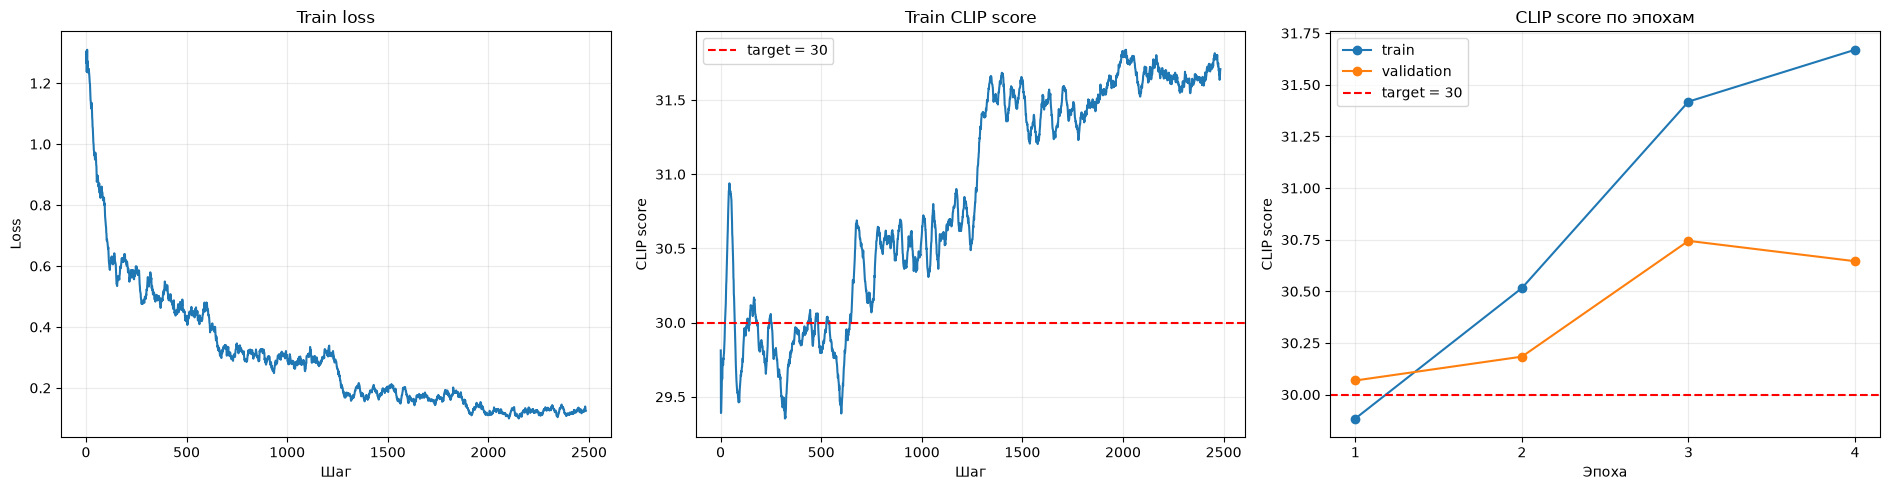

,epoch,train_loss,train_clip_score,validation_clip_score
0,1,0.5736,29.8844,30.0684
1,2,0.3038,30.5159,30.1839
2,3,0.1787,31.4183,30.7443
3,4,0.1235,31.6693,30.6458


In [37]:
batch_metrics = pd.DataFrame(batch_history)
epoch_metrics = pd.DataFrame(epoch_history)
batch_metrics['global_step'] = np.arange(1, len(batch_metrics) + 1)
window = min(25, len(batch_metrics))
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
axes[0].plot(batch_metrics['global_step'], batch_metrics['loss'].rolling(window, min_periods=1).mean())
axes[0].set(title='Train loss', xlabel='Шаг', ylabel='Loss')
axes[1].plot(batch_metrics['global_step'], batch_metrics['clip_score'].rolling(window, min_periods=1).mean())
axes[1].set(title='Train CLIP score', xlabel='Шаг', ylabel='CLIP score')
axes[2].plot(epoch_metrics['epoch'], epoch_metrics['train_clip_score'], marker='o', label='train')
axes[2].plot(epoch_metrics['epoch'], epoch_metrics['validation_clip_score'], marker='o', label='validation')
axes[2].set(title='CLIP score по эпохам', xlabel='Эпоха', ylabel='CLIP score')
axes[2].set_xticks(epoch_metrics['epoch'])
for ax in axes[1:]:
    ax.axhline(30, color='red', linestyle='--', label='target = 30')
for ax in axes:
    ax.grid(alpha=0.25)
axes[1].legend()
axes[2].legend()
plt.tight_layout()
plt.show()
display(epoch_metrics.round(4))

**Результаты обучения.** Loss последовательно снизился: 0.5736 → 0.3038 → 0.1787 → 0.1235. Train CLIP score вырос с 29.88 до 31.66, validation CLIP score — с 30ю06 до максимума 30.74 на третьей эпохе. На четвёртой эпохе validation score немного снизился до 30.64 при продолжающемся улучшении train-метрик — это первый признак переобучения. Поэтому лучшим checkpoint выбран `checkpoints/clip_epoch_3`; checkpoint четвёртой эпохи также сохранён. Целевое значение CLIP score выше 30 достигнуто и на train, и на validation.

![Кривые обучения](../checkpoints/training_curves.png)

# Этап 2. Система поиска товаров

Для быстрого поиска один раз вычислим эмбеддинги всех доступных изображений с помощью лучшего checkpoint третьей эпохи. Индекс будет храниться на диске и повторно загружаться без пересчёта.

In [38]:
BEST_CHECKPOINT = Path('checkpoints/clip_epoch_3')
EMBEDDINGS_PATH = Path('checkpoints/image_embeddings.pt')
INDEX_PATH = Path('checkpoints/image_index.csv')

search_processor = CLIPProcessor.from_pretrained(BEST_CHECKPOINT)
search_model = CLIPModel.from_pretrained(BEST_CHECKPOINT).to(device)
search_model.eval()
print(f'Loaded checkpoint: {BEST_CHECKPOINT.resolve()}')

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 9542.81it/s]


Loaded checkpoint: E:\GitProjects\NLP_Study\Sprint4\checkpoints\clip_epoch_3


## 1. Индекс изображений

Используем весь очищенный датасет без разбиения на train и test. Эмбеддинги нормализуются, поэтому их скалярное произведение с нормализованным текстовым эмбеддингом равно cosine similarity.

In [39]:
class ImageOnlyDataset(Dataset):
    def __init__(self, dataframe, image_dir):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        with Image.open(self.image_dir / row['image']) as image:
            return image.convert('RGB')

def image_collate_fn(images):
    return search_processor(images=images, return_tensors='pt')['pixel_values']

@torch.inference_mode()
def build_image_index(model, dataframe, image_dir, batch_size=256):
    dataset = ImageOnlyDataset(dataframe, image_dir)
    loader = DataLoader(
        dataset, batch_size=batch_size, shuffle=False,
        num_workers=0, pin_memory=device.type == 'cuda',
        collate_fn=image_collate_fn,
    )
    all_embeddings = []
    for pixel_values in tqdm(loader, desc='Image embeddings'):
        pixel_values = pixel_values.to(device, non_blocking=True)
        with torch.amp.autocast(device_type=device.type, enabled=device.type == 'cuda'):
            embeddings = model.get_image_features(pixel_values=pixel_values)
            if not isinstance(embeddings, torch.Tensor):
                embeddings = embeddings.pooler_output
        embeddings = F.normalize(embeddings.float(), dim=-1)
        all_embeddings.append(embeddings.cpu())
    return torch.cat(all_embeddings, dim=0)

if EMBEDDINGS_PATH.exists() and INDEX_PATH.exists():
    image_embeddings = torch.load(EMBEDDINGS_PATH, map_location='cpu')
    image_index = pd.read_csv(INDEX_PATH)
    print('Индекс загружен с диска без повторного вычисления.')
else:
    image_index = clean_df.reset_index(drop=True).copy()
    image_embeddings = build_image_index(search_model, image_index, image_dir)
    torch.save(image_embeddings, EMBEDDINGS_PATH)
    image_index.to_csv(INDEX_PATH, index=False)
    print('Индекс вычислен и сохранён.')

assert len(image_index) == image_embeddings.shape[0]
print(f'Index shape: {tuple(image_embeddings.shape)}')

Image embeddings: 100%|██████████| 173/173 [10:52<00:00,  3.77s/it]


Индекс вычислен и сохранён.
Index shape: (44158, 512)


## 2. Функция поиска

Функция кодирует только новый пользовательский запрос. Все изображения уже представлены векторами, поэтому поиск выполняется быстро.

In [40]:
@torch.inference_mode()
def search_products(
    model, processor, dataframe, image_embeddings,
    query, top_k=5, device=device,
):
    if not isinstance(query, str) or not query.strip():
        raise ValueError('query должен быть непустой строкой')
    if not 1 <= top_k <= len(dataframe):
        raise ValueError(f'top_k должен быть от 1 до {len(dataframe)}')

    text_inputs = processor(
        text=[query.strip()], return_tensors='pt',
        padding=True, truncation=True,
    )
    text_inputs = {key: value.to(device) for key, value in text_inputs.items()}
    text_embedding = model.get_text_features(**text_inputs)
    if not isinstance(text_embedding, torch.Tensor):
        text_embedding = text_embedding.pooler_output
    text_embedding = F.normalize(text_embedding.float(), dim=-1).cpu()

    scores = image_embeddings @ text_embedding.squeeze(0)
    top_scores, top_indices = torch.topk(scores, k=top_k)
    results = dataframe.iloc[top_indices.numpy()].copy()
    results.insert(0, 'rank', np.arange(1, top_k + 1))
    results['score'] = top_scores.numpy()
    return results.reset_index(drop=True)

def plot_search_results(results, image_dir, query, columns=5):
    rows = int(np.ceil(len(results) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 4.5 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, row) in zip(axes, results.iterrows()):
        with Image.open(Path(image_dir) / row['image']) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(
            f"#{int(row['rank'])} | score={row['score']:.3f}\n"
            f"{fill(row['description'], width=38)}",
            fontsize=9,
        )
        ax.axis('off')
    for ax in axes[len(results):]:
        ax.axis('off')
    fig.suptitle(f'Query: {query}', fontsize=15)
    plt.tight_layout()
    plt.show()
    return fig

## 3. Проверка поисковой системы

,rank,image,score,description
0,1,5005.jpg,0.345409,"Composition Coral shorts made of 100% cotton, ..."
1,2,25931.jpg,0.339909,Style Note femella caters to every fashionista...
2,3,33271.jpg,0.334962,"Style Note Pretty and stylish, this skirt from..."
3,4,39314.jpg,0.334962,"Style Note Pretty and stylish, this skirt from..."
4,5,13304.jpg,0.331923,"Composition Red skort made of 100% cotton, has..."


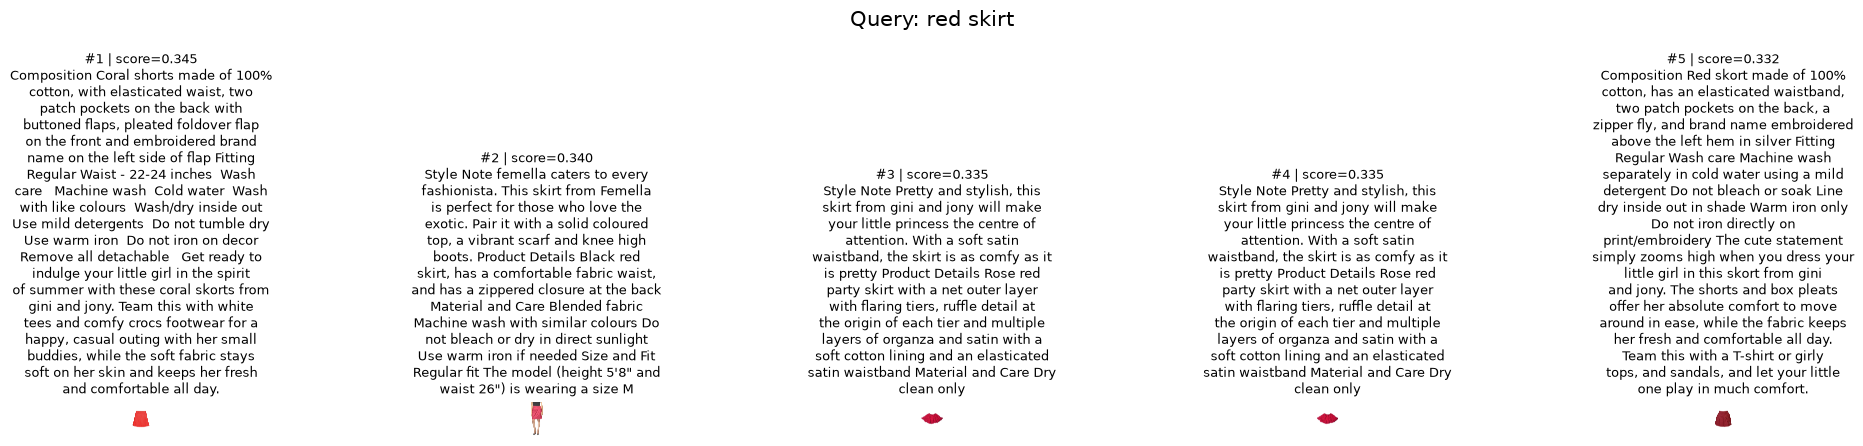

,rank,image,score,description
0,1,17221.jpg,0.333173,"High on style, this pair of sunglasses from un..."
1,2,17227.jpg,0.331093,"High on style, this pair of sunglasses from un..."
2,3,17226.jpg,0.330890,"High on style, this pair of sunglasses from un..."
3,4,17224.jpg,0.330832,"High on style, this pair of sunglasses from un..."
4,5,17229.jpg,0.326288,"High on style, this pair of sunglasses from un..."


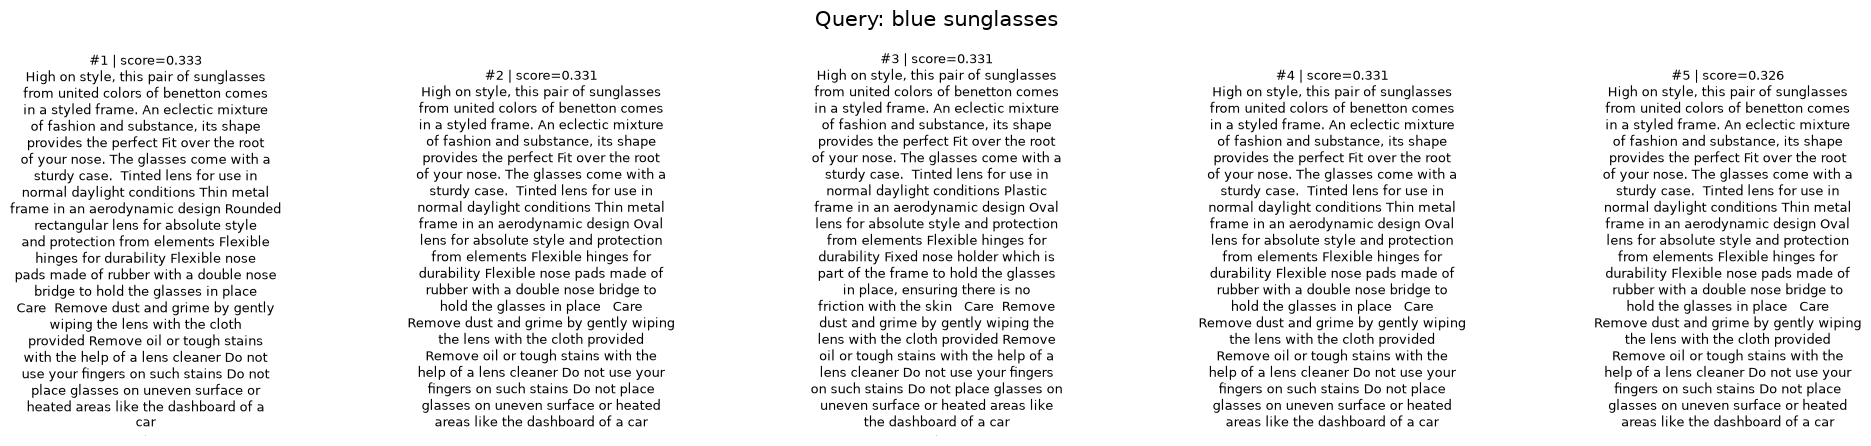

,rank,image,score,description
0,1,7288.jpg,0.315484,Composition Grey melange round neck t-shirt ma...
1,2,4435.jpg,0.306300,Composition Washed gray round neck t-shirt in ...
2,3,4377.jpg,0.298437,Composition Gray round neck t-shirt in 100% co...
3,4,4210.jpg,0.292140,Composition Round neck blue t-shirt in 100% co...
4,5,4352.jpg,0.285723,Composition White round neck t-shirt in 100% c...


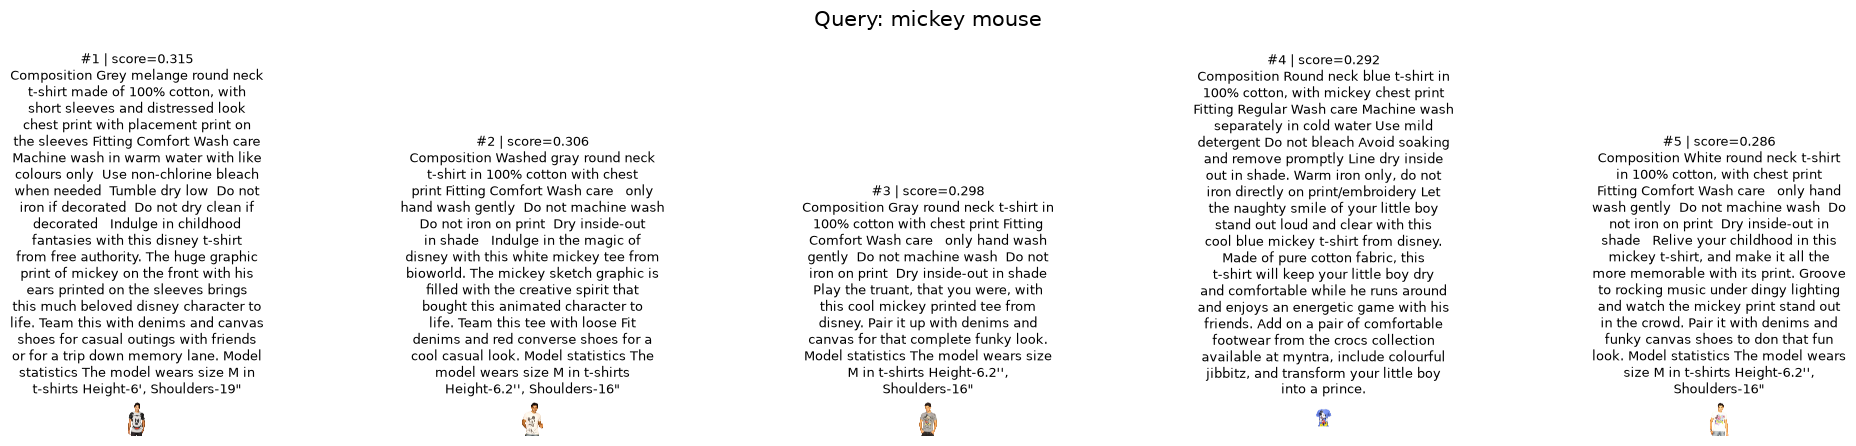

In [41]:
queries = ['red skirt', 'blue sunglasses', 'mickey mouse']
search_results = {}

for query in queries:
    results = search_products(
        search_model, search_processor, image_index,
        image_embeddings, query=query, top_k=5,
    )
    search_results[query] = results
    display(results[['rank', 'image', 'score', 'description']])
    plot_search_results(results, image_dir, query)


**Итог.** Построен индекс из 44 158 нормализованных векторов размерности 512. Изображения кодируются только один раз, а при каждом запросе вычисляется один текстовый эмбеддинг и его cosine similarity со всем индексом. Три проверочных запроса после загрузки модели выполняются примерно за 0.24 секунды. Выдача корректна: запрос `red skirt` возвращает красные юбки, `blue sunglasses` — очки с синими линзами, `mickey mouse` — футболки с Микки-Маусом. Для миллионов товаров этот же интерфейс можно перевести на FAISS без повторного обучения модели.

![Примеры поисковой выдачи](../checkpoints/search_examples.png)